# Tarea 3 — Física Computacional II

**Nombre:** Sofía Soto Ferrada  
**RUT:** 22.261.514-3


In [9]:
# Importamos las librerias que vamos a utilizar
import numpy as np
import matplotlib.pyplot as plt

# Elegimos una semilla para que los numeros aleatorios se repitan

rng = np.random.default_rng(seed=0)

## 1. Simulación de una curva de luz

Generamos 500 tiempos equidistantes entre 0 y 10 años. El flujo comienza en 1, se agrega ruido gaussiano con desviación estándar 0.002 y luego se reducen los valores de flujo 
durante los dos tránsitos indicados.

In [10]:
# Creamos 500 tiempos entre 0 y 10 años
tiempo = np.linspace(0, 10, 500)

# Partimos con un flujo inicial igual a 1
flujo = np.ones(500)


# Agregamos ruido al flujo
sigma_ruido = 0.002
flujo += rng.normal(0, sigma_ruido, tiempo.size)

# Definimos los dos transitos
transito1 = (4.5, 5.0)
transito2 = (7.0, 7.4)

# Bajamos el flujo durante cada tránsito

flujo[(tiempo >= transito1[0]) & (tiempo <= transito1[1])] -= 0.02

flujo[(tiempo >= transito2[0]) & (tiempo <= transito2[1])] -= 0.015


### 1(a). Función para graficar la curva de luz

La función recibe los arreglos de tiempo y flujo. Calcula el flujo medio y el umbral de detección definido como el flujo medio menos tres veces la desviación estándar del ruido. Los puntos bajo ese umbral se destacan con otro color y marcador.

In [3]:
def graficar_curva_luz(tiempo, flujo):
    """
    Grafica la curva de luz completa y destaca los puntos bajo el umbral.

    Parameters
    ----------
    
    tiempo : numpy.ndarray
        Arreglo con los tiempos de observación, en años.
    flujo : numpy.ndarray
        Arreglo con el flujo normalizado medido.

    Returns
    -------
    
    None
        Muestra la figura de la curva de luz.
    """
    # Calculamos el flujo promedio y el umbral
    flujo_medio = np.mean(flujo)
    umbral = flujo_medio - 3 * sigma_ruido

    # Buscamos los puntosque estan bajo el umbral
    puntos_bajo_umbral = flujo < umbral

    # Graficamos todos los puntos de la curva
    plt.figure(figsize=(12, 6))
    plt.plot(tiempo, flujo, ".", color="slateblue", label="Flujo observado")
    plt.plot(tiempo[puntos_bajo_umbral], flujo[puntos_bajo_umbral], "o",
         color="deeppink", markersize=5, label="Flujo bajo el umbral")

    # Agregamos las líneas horizontales de referencia
    plt.axhline(flujo_medio, color="darkcyan", linestyle="--", label="Flujo medio")
    plt.axhline(umbral, color="purple", linestyle=":", label="Umbral de detección")


    
    # Marcamos el inicio y el fin de ambos tránsitos con líneas verticales
    for inicio, fin in [transito1, transito2]:
        plt.axvline(inicio, color="black", linestyle="--", alpha=0.7)
        plt.axvline(fin, color="black", linestyle="--", alpha=0.7)

    # Etiquetamos los ejes, agregamos título y leyenda
    plt.xlabel("Tiempo (años)", fontsize=14)
    plt.ylabel("Flujo normalizado", fontsize=14)
    plt.title("Curva de luz simulada con dos tránsitos", fontsize=16)
    plt.legend(fontsize=14)
    
    plt.tight_layout()
    plt.show()
    

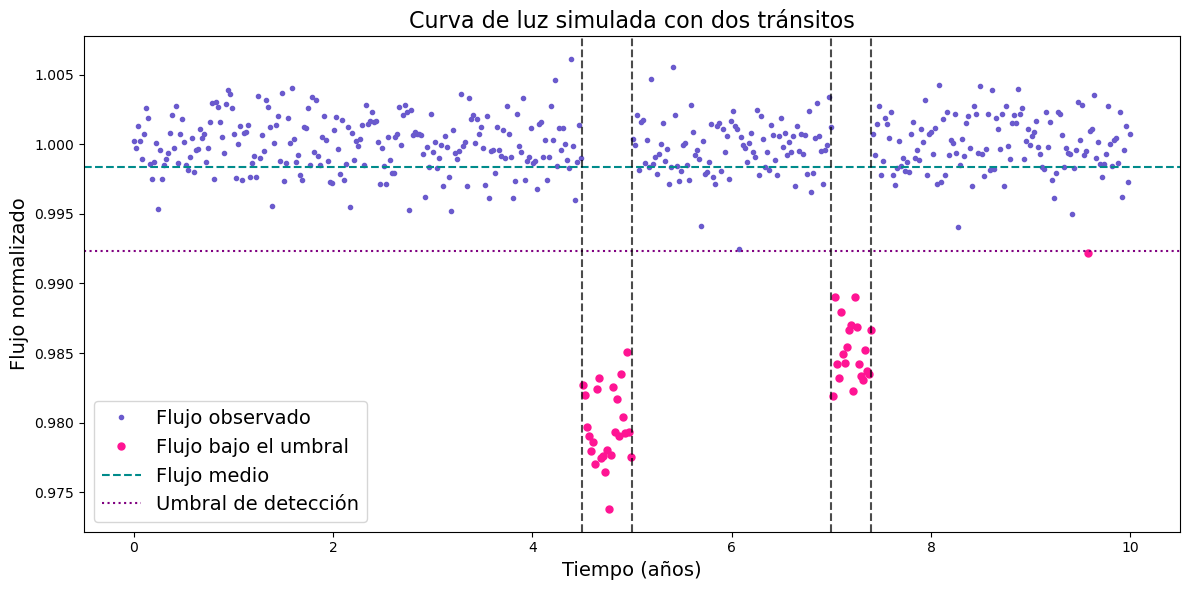

In [11]:
# Mostramos la curva de luz
graficar_curva_luz(tiempo, flujo)


## 2. Imagen astronómica con estrellas gaussianas

Construimos una cuadrícula de coordenadas entre -5 y 5. Cada estrella aporta una distribución gaussiana bidimensional, y la imagen final corresponde a la suma de las intensidades de todas las estrellas.

In [12]:
# Creamos las coordenadas de la imagen
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(x, y)

# # Definimos los datos de las estrellas
I0 = 100
sigma = 0.5

N_estrellas = 5

# Elegimos las posiciones de las cinco estrellas
x0 = rng.uniform(-5, 5, N_estrellas)
y0 = rng.uniform(-5, 5, N_estrellas)

# Sumamos la intensidad de cada estrella en la imagen
imagen = np.zeros_like(X)
for i in range(N_estrellas):
    imagen += I0 * np.exp(-((X - x0[i])**2 + (Y - y0[i])**2) / (2 * sigma**2))
    

### 2(a). Imagen de cinco estrellas

Mostramos la intensidad con `imshow`. Usamos la extensión de las coordenadas para que los ejes indiquen los valores de x e y, en lugar de índices de píxeles.

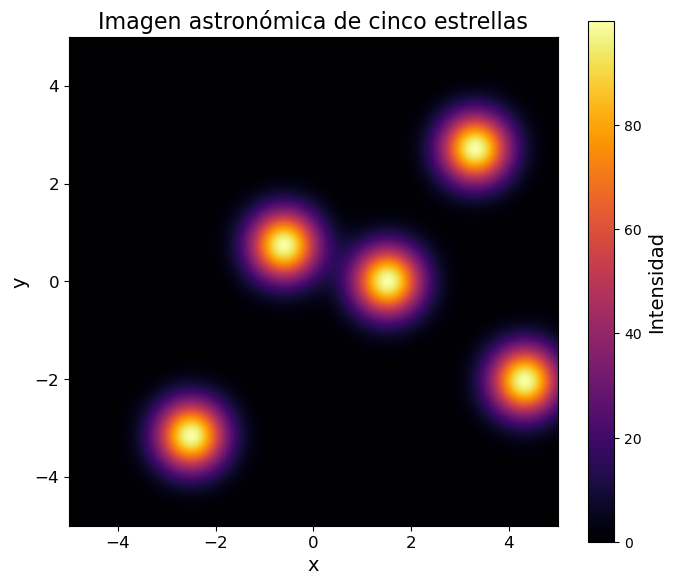

In [13]:
# Mostramos la imagen de las estrellas
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(imagen, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()],
               cmap="inferno", aspect="equal")

# Agregamos la barra de color y los nombres de los ejes

barra = fig.colorbar(im, ax=ax)

barra.set_label("Intensidad", fontsize=14)
ax.set_xlabel("x", fontsize=14)
ax.set_ylabel("y", fontsize=14)
ax.set_title("Imagen astronómica de cinco estrellas", fontsize=16)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

### 2(b). Distancias entre los centros de las estrellas

La función calcula la distancia euclidiana entre cada par de centros. Devuelve una matriz cuadrada: el elemento de la fila i y columna j es la distancia entre la estrella i y la estrella j.

In [14]:
def calcular_distancias(x0, y0):
    """
    Calcula las distancias euclidianas entre todos los pares de estrellas.

    Parameters
    ----------
    x0 : numpy.ndarray
    
        Coordenadas x de los centros de las estrellas.
    y0 : numpy.ndarray
        Coordenadas y de los centros de las estrellas.

    Returns
    -------
    numpy.ndarray
        Matriz de distancias entre cada par de estrellas.
    """
    # Calculamos las diferencias entre las posiciones de las estrellas
    diferencia_x = x0[:, np.newaxis] - x0[np.newaxis, :]
    diferencia_y = y0[:, np.newaxis] - y0[np.newaxis, :]

    # Usamos esas diferencias para calcular las distanciass
    distancias = np.sqrt(diferencia_x**2 + diferencia_y**2)
    return distancias
    

In [15]:

# Calculamos las distancias entre las estrellas

distancias = calcular_distancias(x0, y0)
distancias

array([[0.        , 3.26884775, 8.30409014, 4.88309249, 4.4059321 ],
       [3.26884775, 0.        , 5.13717384, 3.48594418, 2.24984601],
       [8.30409014, 5.13717384, 0.        , 6.94906848, 4.35268675],
       [4.88309249, 3.48594418, 6.94906848, 0.        , 5.67599496],
       [4.4059321 , 2.24984601, 4.35268675, 5.67599496, 0.        ]])

### 2(c). Numeración de las estrellas por intensidad

Numeramos los centros del 1 al 5, desde la menor hasta la mayor intensidad. Como todas las estrellas tienen el mismo valor de intensidad máxima I0, para establecer el orden usamos la intensidad total de la imagen en el píxel más cercano al centro de cada estrella; esto también considera el posible solapamiento entre estrellas.

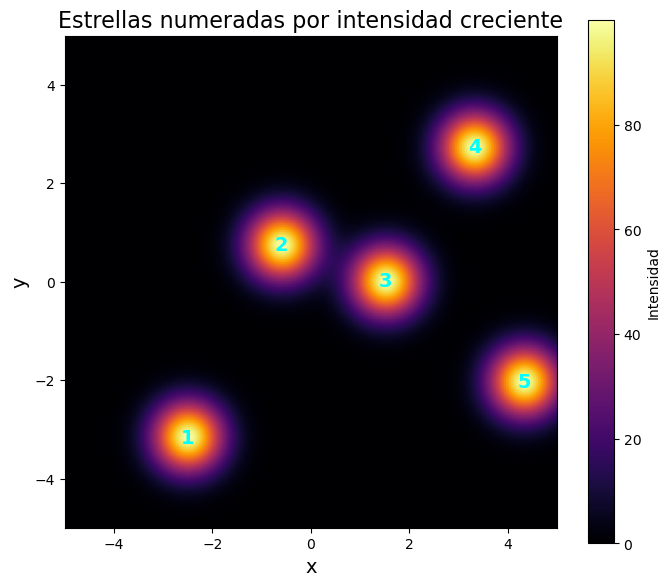

In [16]:
#  Buscamos la intensidad cerca del centro de cada estrella
intensidades_centros = []
for i in range(N_estrellas):
    indice_x = np.argmin(np.abs(x - x0[i]))
    indice_y = np.argmin(np.abs(y - y0[i]))
    
    intensidades_centros.append(imagen[indice_y, indice_x])

# Ordenamos las estrellas desde la menor hasta la mayor intensidad
orden = np.argsort(intensidades_centros)

# Mostramos la imagen y escribimos el número de cada estrella
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(imagen, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()],
               cmap="inferno", aspect="equal")
for numero, indice in enumerate(orden, start=1):
    ax.text(x0[indice], y0[indice], str(numero), color="cyan", fontsize=14,
            ha="center", va="center", fontweight="bold")

# Agregamos la barra de color y los nombres de los ejes

fig.colorbar(im, ax=ax, label="Intensidad")
ax.set_xlabel("x", fontsize=14)
ax.set_ylabel("y", fontsize=14)
ax.set_title("Estrellas numeradas por intensidad creciente", fontsize=16)
plt.tight_layout()
plt.show()

### 2(d). Comparación para distintos valores de σ

Creamos cuatro imágenes de la misma región con σ entre 0.25 y 1.0. Se mantienen las mismas posiciones de las estrellas y la misma escala de color para comparar el efecto de la dispersión.

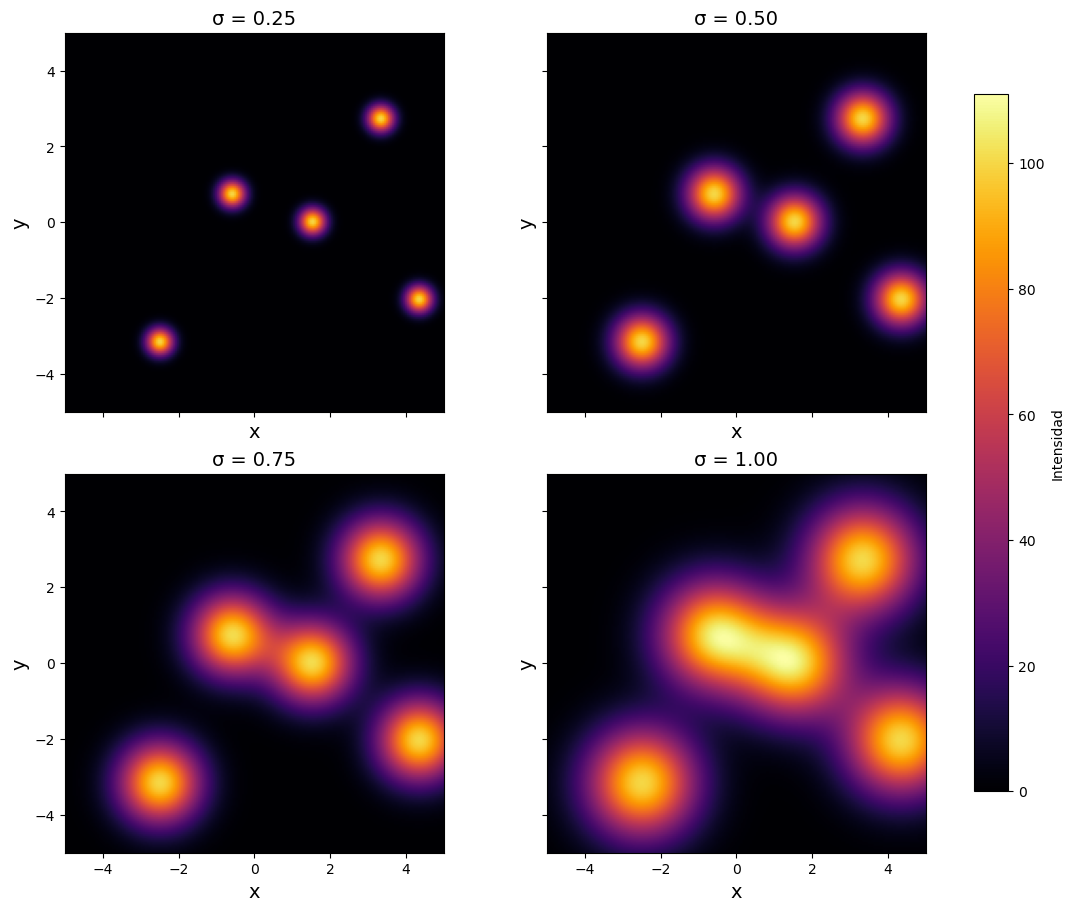

In [17]:
# Elegimos cuatro valores de sigma
valores_sigma = np.linspace(0.25, 1.0, 4)

# Calculamos las imágenes usando las mismas posiciones
imagenes = []
for sigma_actual in valores_sigma:
    imagen_actual = np.zeros_like(X)
    
    for i in range(N_estrellas):
        imagen_actual += I0 * np.exp(-((X - x0[i])**2 + (Y - y0[i])**2) /
                                     (2 * sigma_actual**2))
    imagenes.append(imagen_actual)

# Usamos la misma escala para comparar las imágenes
vmin = min(np.min(im) for im in imagenes)
vmax = max(np.max(im) for im in imagenes)
fig, axs = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True,
                        constrained_layout=True)

# Mostramos las cuatro imágenes
for ax, imagen_actual, sigma_actual in zip(axs.flat, imagenes, valores_sigma):
    im = ax.imshow(imagen_actual, origin="lower",
                   extent=[x.min(), x.max(), y.min(), y.max()],
                   cmap="inferno", vmin=vmin, vmax=vmax, aspect="equal")
    ax.set_title(f"σ = {sigma_actual:.2f}", fontsize=14)
    ax.set_xlabel("x", fontsize=14)
    ax.set_ylabel("y", fontsize=14)

# Agregamos una barra de color para todas las imágenes

fig.colorbar(im, ax=axs, label="Intensidad", shrink=0.85)
plt.show()

**¿Qué ocurre al cambiar σ?**

Cuando aumenta el valor de sigma, las estrellas se ven más grandes porque la luz se distribuye en una zona más amplia. También puede ocurrir que las estrellas que están más cerca se mezclen más entre sí.
